# 06. Final pipeline
Model choice from 02–05: **RT-DETR-L** has the best validation mAP under the same 1.25 GPU-hour budget
(0.297 vs 0.257 for the best CNN, YOLO11m at 1536) and the best public score (0.294).

In this notebook the model family is fixed and we change one thing at a time:
1. **Inference** (no training): horizontal-flip TTA and a WBF ensemble with YOLO11m-1536.
2. **Data** (same model and budget): masking of ignored regions, frame step.
3. **Temporal smoothing** (bonus): rescoring detections with neighbouring video frames.
4. **Final models** trained on train + val clips with the selected settings, and the test submissions.

All selection is done on the same validation frames as in 02–05 (420 frames from 7 held-out clips), except the
temporal step, which needs consecutive frames (section 3).

In [1]:
import os; os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
%load_ext autoreload
%autoreload 2
import sys, json, pickle, subprocess, itertools
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ultralytics import RTDETR, YOLO
from common import (PROC, ROOT, PROJECT, CHECKPOINTS, seed_everything, load_results, coco_evaluate, save_results,
                    wbf_merge, image_sizes, load_split, select_frames, build_yolo_dataset, make_coco_gt,
                    temporal_rescore, write_submission)
import yolo_utils as yu

seed_everything()
VAL_GT = PROC / "val_gt.json"
SIZES = image_sizes(VAL_GT)
ITEMS = yu.val_items(VAL_GT)
BUDGET_H = 1.25
RT_CFG = dict(model="rtdetr-l", queries=300, denoising=100, budget_h=BUDGET_H, batch=1)
KEYS = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]
COMP = "multiple-object-video-detection-hw-2-ucu-ai-2026"
SUBMIT = True          # set to False to only write the csv files without sending them to Kaggle

def load_preds(name):
    return pickle.load(open(CHECKPOINTS / f"{name}_val_preds.pkl", "rb"))

def cached(path, fn):
    """Compute predictions once and keep them in checkpoints/ (inference on 400+ frames takes minutes)."""
    path = CHECKPOINTS / path
    if path.exists():
        return pickle.load(open(path, "rb"))
    out = fn()
    pickle.dump(out, open(path, "wb"))
    return out

def submit(path, message):
    if SUBMIT:
        subprocess.run(["kaggle", "competitions", "submit", "-c", COMP, "-f", str(path), "-m", message], check=True)

## 1. Inference strategies (model fixed: `rtdetr_base`, trained on train clips only)
* **Flip TTA**: predict on the frame and on its horizontal mirror, map the mirrored boxes back, merge both sets.
* **Ensemble** with **YOLO11m-1536** (`yolo_1536`): a different family (CNN, anchor-free, NMS-based), so its errors
  should be less correlated with RT-DETR's; it was also the best CNN on medium objects.

Merging uses **Weighted Boxes Fusion** (Solovyev et al., 2019, package `ensemble-boxes`): boxes of the same class
that overlap above an IoU threshold are averaged (weighted by score) instead of suppressed. The grid below is kept
small on purpose: tuning many ensemble parameters on 7 validation clips would overfit them.

In [2]:
rt_base = RTDETR(str(yu.RUNS / "rtdetr_base" / "weights" / "best.pt"))
P_VAL = {"rt": load_preds("rtdetr_base"),
         "rt_flip": cached("rtdetr_base_flip_val_preds.pkl", lambda: yu.predict_ultra_hflip(rt_base, ITEMS, imgsz=1280)),
         "yolo": load_preds("yolo_1536")}

def apply_recipe(P, sizes, flip, yolo, w_rt=2, iou=0.6):
    """One inference recipe: RT-DETR alone or merged (WBF) with its flipped pass and/or YOLO11m-1536."""
    parts, weights = [P["rt"]], [w_rt]
    if flip:
        parts.append(P["rt_flip"]); weights.append(w_rt)
    if yolo:
        parts.append(P["yolo"]); weights.append(1)
    return P["rt"] if len(parts) == 1 else wbf_merge(parts, sizes, weights=weights, iou_thr=iou)

grid = [dict(flip=False, yolo=False)]
grid += [dict(flip=True, yolo=False, iou=t) for t in (0.55, 0.65)]
grid += [dict(flip=f, yolo=True, w_rt=w, iou=t) for f in (False, True) for w in (1, 2, 3) for t in (0.55, 0.65)]
rows = []
for g in grid:
    m = coco_evaluate(VAL_GT, apply_recipe(P_VAL, SIZES, **g))
    rows.append({**g, **{k: m[k] for k in KEYS}})
inf_tab = pd.DataFrame(rows).sort_values("mAP", ascending=False)
display(inf_tab.round(4))

BEST_RECIPE = {k: v for k, v in inf_tab.iloc[0][["flip", "yolo", "w_rt", "iou"]].items() if pd.notna(v)}
BEST_RECIPE = {k: (bool(v) if k in ("flip", "yolo") else float(v) if k == "iou" else int(v)) for k, v in BEST_RECIPE.items()}
print("selected inference recipe:", BEST_RECIPE)
best_val = apply_recipe(P_VAL, SIZES, **BEST_RECIPE)
save_results("final_inference_recipe_val", coco_evaluate(VAL_GT, best_val), recipe=str(BEST_RECIPE),
             models="rtdetr_base + yolo_1536 (trained on train clips)")

,flip,yolo,mAP,AP50,AP75,AP_small,AP_medium,AP_large,iou,w_rt
10,True,True,0.3206,0.5826,0.3083,0.1444,0.2911,0.4946,0.65,1.0
4,False,True,0.3189,0.5782,0.3082,0.1526,0.2870,0.4842,0.65,1.0
12,True,True,0.3137,0.5696,0.3019,0.1318,0.2868,0.4859,0.65,2.0
9,True,True,0.3136,0.5726,0.2994,0.1398,0.2841,0.4857,0.55,1.0
3,False,True,0.3114,0.5685,0.2984,0.1461,0.2794,0.4757,0.55,1.0
6,False,True,0.3113,0.5635,0.3032,0.1440,0.2839,0.4788,0.65,2.0
14,True,True,0.3096,0.5619,0.2988,0.1278,0.2832,0.4839,0.65,3.0
11,True,True,0.3054,0.5560,0.2927,0.1270,0.2786,0.4769,0.55,2.0
8,False,True,0.3053,0.5536,0.2978,0.1380,0.2798,0.4755,0.65,3.0
5,False,True,0.3018,0.5488,0.2937,0.1362,0.2741,0.4698,0.55,2.0


selected inference recipe: {'flip': True, 'yolo': True, 'w_rt': 1, 'iou': 0.65}


{'name': 'final_inference_recipe_val',
 'mAP': 0.3206,
 'AP50': 0.5826,
 'AP75': 0.3083,
 'AP_small': 0.1444,
 'AP_medium': 0.2911,
 'AP_large': 0.4946,
 'AP_person': 0.2971,
 'AP_bicycle': 0.3139,
 'AP_car': 0.5544,
 'AP_van': 0.2925,
 'AP_truck': 0.3763,
 'AP_tricycle': 0.2955,
 'AP_bus': 0.2819,
 'AP_motor': 0.1528,
 'recipe': "{'flip': True, 'yolo': True, 'w_rt': 1, 'iou': 0.65}",
 'models': 'rtdetr_base + yolo_1536 (trained on train clips)'}

## 2. Data strategies (model and budget fixed: RT-DETR-L, 1.25 h)
* **No masking** (`s10_nomask`): ignored regions are not painted grey and objects inside them are kept.
  Tests the preprocessing choice from 01_data.
* **Frame step 5** (`s5`): twice as many frames from the same 56 clips. Tests whether the model is limited by the
  number of frames or by the number of distinct scenes (02–05 all peaked early, which suggests the latter).

In [3]:
imgs_tr, obj_tr, ign_tr = load_split("train")
imgs_va, obj_va, ign_va = load_split("val")
val_frames = select_frames(imgs_va, per_clip=60)            # the same validation frames as everywhere
for name, step, mask in [("s10_nomask", 10, False), ("s5", 5, True)]:
    if not (PROC / name / "data.yaml").exists():
        tr = select_frames(imgs_tr, step=step)
        st = build_yolo_dataset(name, {"train": ("train", tr, obj_tr, ign_tr, mask),
                                       "val": ("val", val_frames, obj_va, ign_va, False)})
        print(name, st.groupby("part")[["kept", "dropped"]].sum().to_dict())

s10_nomask {'kept': {'train': 112264, 'val': 20624}, 'dropped': {'train': 0, 'val': 0}}
s5 {'kept': {'train': 220287, 'val': 20624}, 'dropped': {'train': 2592, 'val': 0}}


In [4]:
# ~1.25 h
w_nomask = yu.train_ultra("rtdetr_nomask", "rtdetr-l.pt", kind="rtdetr", imgsz=1280, batch=1, hours=BUDGET_H,
                          data=str(PROC / "s10_nomask" / "data.yaml"))
res_nomask, _ = yu.evaluate_ultra("rtdetr_nomask", w_nomask, VAL_GT, {**RT_CFG, "data": "s10, no masking"},
                                  kind="rtdetr", imgsz=1280)

New https://pypi.org/project/ultralytics/8.4.207 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/s10_nomask/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, l

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      3.08G      1.141     0.5073     0.2647         58       1280: 100% ━━━━━━━━━━━━ 2446/2446 6.3it/s 6:260.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 9.4it/s 22.4s0.1ss
                   all        420      20624      0.448      0.448      0.407      0.214
Closing dataloader mosaic

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/11       3.1G     0.9751     0.4671     0.1234         77       1280: 0% ──────────── 1/2446 2.0it/s 0.5s<20:33

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/11       3.1G     0.6868     0.4983    0.09404         53       1280: 100% ━━━━━━━━━━━━ 2446/2446 6.5it/s 6:190.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 9.6it/s 21.9s0.1sss
                   all        420      20624      0.563      0.482      0.461      0.254

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/12       3.1G     0.6692     0.5257    0.06606         83       1280: 0% ──────────── 1/2446 2.0it/s 0.3s<20:23

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (15 outputs left out)

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      11/12       3.1G     0.5208     0.4355    0.05806         62       1280: 100% ━━━━━━━━━━━━ 2446/2446 6.4it/s 6:200.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 9.8it/s 21.5s0.1ss
                   all        420      20624      0.608      0.476      0.485       0.27

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      12/12       3.1G     0.5623     0.4571    0.05605          6       1280: 0% ──────────── 1/2446 1.9it/s 0.3s<21:35

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      12/12       3.1G     0.5223     0.4304    0.05787         63       1280: 58% ━━━━━━━───── 1440/2446 7.3it/s 3:44<2:18
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 9.5it/s 22.2s0.1ss
                   all        420      20624      0.596      0.474      0.473      0.261

12 epochs completed in 1.257 hours.
Optimizer stripped from /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_nomask/weights/last.pt, 66.5MB
Optimizer stripped from /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_nomask/weights/best.pt, 66.5MB

Validating /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_nomask/weights/best.pt...
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7708MiB)
rt-detr-l summary (fused): 315 layers, 32,000,180 parameters, 0 gradients, 105.4 GFLOPs
                 Class   

In [8]:
# ~1.25 h
w_s5 = yu.train_ultra("rtdetr_s5", "rtdetr-l.pt", kind="rtdetr", imgsz=1280, batch=1, hours=BUDGET_H,
                      data=str(PROC / "s5" / "data.yaml"))
res_s5, _ = yu.evaluate_ultra("rtdetr_s5", w_s5, VAL_GT, {**RT_CFG, "data": "s5 (every 5th frame)"},
                              kind="rtdetr", imgsz=1280)

data_tab = load_results().set_index("name").loc[["rtdetr_base", "rtdetr_nomask", "rtdetr_s5"], KEYS + ["epochs_done"]]
display(data_tab)
DATA_OPTIONS = {"rtdetr_base": (10, True), "rtdetr_nomask": (10, False), "rtdetr_s5": (5, True)}
close = data_tab[data_tab["mAP"] >= data_tab["mAP"].max() - 0.005]
BEST_DATA = close["AP_small"].idxmax()
TRAIN_STEP, MASK = DATA_OPTIONS[BEST_DATA]
print(f"selected data setting: {BEST_DATA} -> frame step {TRAIN_STEP}, masking {MASK}")

rtdetr_s5: already trained, using /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_s5/weights/best.pt


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,epochs_done
name,,,,,,,
rtdetr_base,0.2969,0.5400,0.2876,0.1326,0.2681,0.4592,13.0
rtdetr_nomask,0.2981,0.5463,0.2881,0.0948,0.2675,0.4805,12.0
rtdetr_s5,0.2831,0.5164,0.2764,0.1133,0.2526,0.4639,7.0


selected data setting: rtdetr_base -> frame step 10, masking True


## 3. Temporal smoothing (bonus: data temporality)
Test frames are consecutive video frames, but our validation frames are 60 *spaced* frames per clip. To evaluate a
temporal method we therefore build a second validation set: **60 consecutive frames from the middle of every
validation clip** (same 7 held-out clips, models trained on train clips only).

Method (`common.temporal_rescore`, in the spirit of Seq-NMS / T-CNN tubelet rescoring): for every detection we look
at the frames t±1..t±window and take the score of the best matching detection there (same class, IoU >= 0.5).
New score = alpha * own score + (1 - alpha) * mean neighbour score. Objects that are detected consistently keep
their score; isolated false positives lose it. Boxes are not changed, so this only affects the ranking.

In [12]:
# consecutive validation segment: 60 frames from the middle of each validation clip
seq = []
for clip, g in imgs_va.sort_values("frame_id").groupby("video"):
    mid = len(g) // 2
    seq.append(g.iloc[max(0, mid - 30): mid + 30])
seq_frames = pd.concat(seq, ignore_index=True)
SEQ_GT = make_coco_gt(seq_frames, obj_va, ign_va, "val", PROC / "val_seq_gt.json")
SEQ_ITEMS, SEQ_SIZES = yu.val_items(SEQ_GT), image_sizes(SEQ_GT)
SEQ_FRAME_OF = {r.image_id: (r.video, r.frame_id) for r in seq_frames.itertuples()}
print(len(seq_frames), "consecutive frames from", seq_frames.video.nunique(), "clips")

yolo_1536 = YOLO(str(yu.RUNS / "yolo_1536" / "weights" / "best.pt"))
P_SEQ = {"rt": cached("rtdetr_base_seq_preds.pkl", lambda: yu.predict_ultra(rt_base, SEQ_ITEMS, imgsz=1280)[0]),
         "rt_flip": cached("rtdetr_base_flip_seq_preds.pkl", lambda: yu.predict_ultra_hflip(rt_base, SEQ_ITEMS, imgsz=1280)),
         "yolo": cached("yolo_1536_seq_preds.pkl", lambda: yu.predict_ultra(yolo_1536, SEQ_ITEMS, imgsz=1536)[0])}

420 consecutive frames from 7 clips


In [13]:
seq_single = P_SEQ["rt"]
seq_recipe = apply_recipe(P_SEQ, SEQ_SIZES, **BEST_RECIPE)
rows = [{"setting": "rtdetr single pass", **coco_evaluate(SEQ_GT, seq_single)},
        {"setting": f"inference recipe {BEST_RECIPE}", **coco_evaluate(SEQ_GT, seq_recipe)}]
for window, alpha in itertools.product([1, 2, 3], [0.4, 0.6, 0.8]):
    m = coco_evaluate(SEQ_GT, temporal_rescore(seq_recipe, SEQ_FRAME_OF, window=window, alpha=alpha))
    rows.append({"setting": f"recipe + temporal (window={window}, alpha={alpha})", "window": window, "alpha": alpha, **m})
temp_tab = pd.DataFrame(rows)
display(temp_tab[["setting"] + KEYS].round(4))

best_t = temp_tab.dropna(subset=["window"]).sort_values("mAP", ascending=False).iloc[0]
USE_TEMPORAL = best_t["mAP"] > temp_tab.loc[1, "mAP"]
TEMPORAL = dict(window=int(best_t["window"]), alpha=float(best_t["alpha"])) if USE_TEMPORAL else None
print("temporal smoothing:", TEMPORAL if USE_TEMPORAL else "not used (no gain on the consecutive validation frames)")

,setting,mAP,AP50,AP75,AP_small,AP_medium,AP_large
0,rtdetr single pass,0.2283,0.4546,0.2006,0.1316,0.2495,0.3389
1,"inference recipe {'flip': True, 'yolo': True, ...",0.2398,0.4799,0.2096,0.1420,0.2521,0.3719
2,"recipe + temporal (window=1, alpha=0.4)",0.2394,0.4720,0.2127,0.1363,0.2527,0.3791
3,"recipe + temporal (window=1, alpha=0.6)",0.2431,0.4836,0.2136,0.1413,0.2569,0.3800
4,"recipe + temporal (window=1, alpha=0.8)",0.2426,0.4847,0.2124,0.1425,0.2561,0.3771
5,"recipe + temporal (window=2, alpha=0.4)",0.2404,0.4735,0.2133,0.1377,0.2538,0.3844
6,"recipe + temporal (window=2, alpha=0.6)",0.2441,0.4849,0.2151,0.1429,0.2579,0.3838
7,"recipe + temporal (window=2, alpha=0.8)",0.2433,0.4855,0.2136,0.1437,0.2569,0.3789
8,"recipe + temporal (window=3, alpha=0.4)",0.2364,0.4694,0.2072,0.1372,0.2458,0.3877
9,"recipe + temporal (window=3, alpha=0.6)",0.2418,0.4839,0.2106,0.1429,0.2522,0.3856


temporal smoothing: {'window': 2, 'alpha': 0.6}


## 4. Final models: train + validation clips
The model is limited by the number of distinct scenes (02–05 peak early; section 2), so the final models are trained
on all 63 labelled clips (56 train + 7 val) with the selected data setting and the same 1.25 h budget.
There is no held-out data left for them, so (1) every choice was made above with models trained on train clips only,
and (2) we take the **last** checkpoint instead of the "best" one: Ultralytics' best-epoch selection would now use
frames the model was trained on. This is safe here because RT-DETR's validation curve was flat after ~0.5 h (05).

In [14]:
full_name = f"full_s{TRAIN_STEP}{'' if MASK else '_nomask'}"
if not (PROC / full_name / "data.yaml").exists():
    tr = select_frames(imgs_tr, step=TRAIN_STEP)
    va = select_frames(imgs_va, step=TRAIN_STEP)
    st = build_yolo_dataset(full_name, {"train": ("train", tr, obj_tr, ign_tr, MASK),
                                        "train_val": ("val", va, obj_va, ign_va, MASK),
                                        "val": ("val", val_frames, obj_va, ign_va, False)})
    print(st.groupby("part")[["kept", "dropped"]].sum())
# both labelled parts are used for training; "val" is only Ultralytics' progress monitor (it is inside train now)
yaml_path = PROC / full_name / "data.yaml"
yaml_path.write_text(yaml_path.read_text().replace("train: images/train\n", "train: [images/train, images/train_val]\n"))
FULL_YAML = str(yaml_path)
print(yaml_path.read_text())

             kept  dropped
part                      
train      110854     1410
train_val   11430      140
val         20624        0
path: /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/full_s10
train: [images/train, images/train_val]
val: images/val
nc: 8
names: ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]



In [15]:
# ~1.25 h
yu.train_ultra("rtdetr_final", "rtdetr-l.pt", kind="rtdetr", imgsz=1280, batch=1, hours=BUDGET_H, data=FULL_YAML)
W_RT_FINAL = yu.RUNS / "rtdetr_final" / "weights" / "last.pt"

New https://pypi.org/project/ultralytics/8.4.207 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/full_s10/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100       3.2G      1.079     0.5042     0.2403         99       1280: 100% ━━━━━━━━━━━━ 2734/2734 6.9it/s 6:390.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 11.2it/s 18.8s0.1s
                   all        420      20624      0.604      0.547      0.579      0.325
Closing dataloader mosaic

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/11      3.23G      0.634     0.5754    0.08446         61       1280: 0% ──────────── 1/2734 2.3it/s 0.5s<19:50

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/11      3.23G     0.6649     0.4916    0.08883         18       1280: 100% ━━━━━━━━━━━━ 2734/2734 7.5it/s 6:040.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 11.4it/s 18.4s0.1s
                   all        420      20624      0.649      0.657      0.665      0.389

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/12      3.23G     0.6834     0.4622     0.0883         39       1280: 0% ──────────── 1/2734 2.3it/s 0.3s<20:13

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (15 outputs left out)

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      11/12      3.23G     0.5251     0.4331    0.05717         15       1280: 100% ━━━━━━━━━━━━ 2734/2734 7.3it/s 6:140.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 10.1it/s 20.8s0.2ss
                   all        420      20624      0.741      0.751      0.778       0.46

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      12/12      3.23G      0.518     0.4442    0.04212        105       1280: 0% ──────────── 1/2734 2.1it/s 0.3s<22:09

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      12/12      3.23G     0.5176       0.43     0.0566         13       1280: 61% ━━━━━━━───── 1682/2734 7.3it/s 4:09<2:24
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 9.8it/s 21.3s0.1sss
                   all        420      20624      0.771      0.771      0.795      0.472

12 epochs completed in 1.259 hours.
Optimizer stripped from /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_final/weights/last.pt, 66.5MB
Optimizer stripped from /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_final/weights/best.pt, 66.5MB

Validating /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_final/weights/best.pt...
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7708MiB)
rt-detr-l summary (fused): 315 layers, 32,000,180 parameters, 0 gradients, 105.4 GFLOPs
                 Class     

In [16]:
# ~1.25 h, only needed if the selected recipe uses YOLO
if BEST_RECIPE.get("yolo"):
    yu.train_ultra("yolo_final", "yolo11m.pt", imgsz=1536, batch=2, hours=BUDGET_H, data=FULL_YAML)
    W_YOLO_FINAL = yu.RUNS / "yolo_final" / "weights" / "last.pt"

New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/full_s10/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1536, iou=0.7, kobj=1.0, line_width=None, lr0

[W1108 17:53:57.247403577 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 43319296, total: 8082096128).
[W1108 17:53:57.249123824 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 43319296, total: 8082096128).


      1/100      6.41G      1.749      2.545      1.179        251       1536: 0% ──────────── 2/1367 1.8it/s 1.7s<12:19

[W1108 17:53:57.523693191 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 36110336, total: 8082096128).
[W1108 17:53:57.524210751 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 42401792, total: 8082096128).
[W1108 17:53:57.528167100 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 42401792, total: 8082096128).


      1/100      6.41G      1.812      2.452      1.306        132       1536: 0% ──────────── 5/1367 3.1it/s 2.5s<7:239

[W1108 17:53:58.633066825 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 36110336, total: 8082096128).
[W1108 17:53:58.636183054 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 42401792, total: 8082096128).
[W1108 17:53:58.640063609 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 42401792, total: 8082096128).


... (117 outputs left out)

[W1108 17:54:42.252467380 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 37552128, total: 8082096128).
[W1108 17:54:42.413427935 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 2097152 bytes (free: 27066368, total: 8082096128).


      1/100      6.44G      1.722       1.44      1.229        161       1536: 13% ━╸────────── 191/1367 4.3it/s 46.8s<4:31WARNING ⚠️ CUDA out of memory with batch=2. Reducing to batch=1 and retrying (1/3).


[W1108 17:54:43.954916367 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 37552128, total: 8082096128).
[W1108 17:54:43.955333426 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 41746432, total: 8082096128).
[W1108 17:54:43.964857588 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 37552128, total: 8082096128).
[W1108 17:54:43.971068179 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 39649280, total: 8082096128).


train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6822.9±4499.8 MB/s, size: 483.7 KB)
train: Scanning /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/full_s10/labels/train.cache... 2734 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2734/2734 1.4Git/s 0.0s
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5197.2±674.9 MB/s, size: 459.6 KB)
val: Scanning /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/full_s10/labels/val.cache... 420 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 420/420 220.2Mit/s 0.0s
      1/100      6.44G      1.722       1.44      1.229        161       1536: 14% ━╸────────── 192/1367 3.4it/s 47.6s<5:41

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      1/100      6.02G      1.667      1.218      1.241        182       1536: 100% ━━━━━━━━━━━━ 2734/2734 8.8it/s 5:120.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)

## 5. Test predictions and submissions
Three submissions, from simple to full, so the public score shows the effect of each step:
* **A**: final RT-DETR alone;
* **B**: final RT-DETR + selected inference recipe (TTA / ensemble);
* **C**: B + temporal smoothing (if it helped in section 3).

In [17]:
test_df = pd.read_csv(ROOT / "test_images.csv")
T_ITEMS = yu.test_items(test_df)
T_SIZES = {r.image_id: (r.width, r.height) for r in test_df.itertuples()}
T_FRAME_OF = {r.image_id: (r.clip, r.frame) for r in test_df.itertuples()}

rt_final = RTDETR(str(W_RT_FINAL))
P_TEST = {"rt": cached("rtdetr_final_test_preds.pkl", lambda: yu.predict_ultra(rt_final, T_ITEMS, imgsz=1280)[0])}
if BEST_RECIPE.get("flip"):
    P_TEST["rt_flip"] = cached("rtdetr_final_flip_test_preds.pkl", lambda: yu.predict_ultra_hflip(rt_final, T_ITEMS, imgsz=1280))
if BEST_RECIPE.get("yolo"):
    yolo_final = YOLO(str(W_YOLO_FINAL))
    P_TEST["yolo"] = cached("yolo_final_test_preds.pkl", lambda: yu.predict_ultra(yolo_final, T_ITEMS, imgsz=1536)[0])

In [18]:
SUB = PROJECT / "submissions"
sub_a = P_TEST["rt"]
write_submission(sub_a, test_df, SUB / "final_A_rtdetr.csv")
submit(SUB / "final_A_rtdetr.csv", "Final A: RT-DETR-L trained on train+val")

sub_b = apply_recipe(P_TEST, T_SIZES, **BEST_RECIPE)
write_submission(sub_b, test_df, SUB / "final_B_recipe.csv")
submit(SUB / "final_B_recipe.csv", f"Final B: RT-DETR train+val + {BEST_RECIPE}")

if USE_TEMPORAL:
    sub_c = temporal_rescore(sub_b, T_FRAME_OF, **TEMPORAL)
    write_submission(sub_c, test_df, SUB / "final_C_temporal.csv")
    submit(SUB / "final_C_temporal.csv", f"Final C: B + temporal {TEMPORAL}")

100%|██████████| 34.0M/34.0M [00:05<00:00, 6.12MB/s]


Submission ref: 58135889
9 submissions remaining today.
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026

100%|██████████| 52.8M/52.8M [00:07<00:00, 7.35MB/s]


Submission ref: 58135918
8 submissions remaining today.
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026

100%|██████████| 52.8M/52.8M [00:09<00:00, 6.14MB/s]


Submission ref: 58135980
7 submissions remaining today.
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026

### 5b. Correction after the public leaderboard
Submission B (ensemble chosen on validation) scored 0.008 below A on the public leaderboard, while the
RT-DETR model alone (A) and temporal smoothing (C vs B: +0.004, the same gain as on the consecutive validation frames)
transferred well. YOLO models already showed a large validation -> public drop (yolo_base 0.241 -> 0.200), RT-DETR
almost none (0.297 -> 0.294): YOLO generalises worse to the low-resolution test clips, which our 7 validation clips
do not contain. We therefore (D) drop YOLO and (F) keep it only with a low weight.

In [20]:
# D: RT-DETR alone + temporal smoothing;  F: ensemble with RT-DETR weighted 3:3:1 + temporal smoothing
recipe_f = dict(flip=True, yolo=True, w_rt=3, iou=0.65)
tw = dict(window=2, alpha=0.6)

# the same settings on the consecutive validation frames (models trained on train clips only)
for name, p in [("D: rtdetr + temporal", temporal_rescore(P_SEQ["rt"], SEQ_FRAME_OF, **tw)),
                ("F: rtdetr x3 + flip + yolo + temporal",
                 temporal_rescore(apply_recipe(P_SEQ, SEQ_SIZES, **recipe_f), SEQ_FRAME_OF, **tw))]:
    m = coco_evaluate(SEQ_GT, p)
    print(f"{name:40s} seq-val mAP {m['mAP']:.4f}  AP_small {m['AP_small']:.4f}")

sub_d = temporal_rescore(P_TEST["rt"], T_FRAME_OF, **tw)
write_submission(sub_d, test_df, SUB / "final_D_rtdetr_temporal.csv")
submit(SUB / "final_D_rtdetr_temporal.csv", "Final D: RT-DETR train+val + temporal (window 2, alpha 0.6)")

sub_f = temporal_rescore(apply_recipe(P_TEST, T_SIZES, **recipe_f), T_FRAME_OF, **tw)
write_submission(sub_f, test_df, SUB / "final_F_ens_w3_temporal.csv")
submit(SUB / "final_F_ens_w3_temporal.csv", "Final F: RT-DETR x3 + flip + YOLO x1 (WBF 0.65) + temporal")

D: rtdetr + temporal                     seq-val mAP 0.2288  AP_small 0.1352
F: rtdetr x3 + flip + yolo + temporal    seq-val mAP 0.2351  AP_small 0.1331


100%|██████████| 34.0M/34.0M [00:06<00:00, 5.24MB/s]


Submission ref: 58137546
6 submissions remaining today.
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026

100%|██████████| 52.8M/52.8M [00:07<00:00, 7.62MB/s]


Submission ref: 58137642
5 submissions remaining today.
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026

## 6. Summary of all models
Validation metrics of every run from 02–06 (same 420 frames, same evaluator). Speed is model time per frame on an
RTX 5070 Laptop GPU (torchvision: mixed precision, Ultralytics: inference + NMS, both at batch 1).

,family,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_image
name,,,,,,,,
final_inference_recipe_val,final pipeline,0.3206,0.5826,0.3083,0.1444,0.2911,0.4946,NaN
retina_focal,one-stage anchor-based,0.2108,0.3969,0.2007,0.0613,0.1826,0.3946,28.6
retina_base,one-stage anchor-based,0.2065,0.3845,0.1950,0.0716,0.1769,0.3858,28.7
retina_anchors,one-stage anchor-based,0.1871,0.3931,0.1559,0.0744,0.1737,0.3269,28.6
yolo_1536,one-stage anchor-free,0.2567,0.4983,0.2302,0.1341,0.2558,0.3829,34.1
yolo_base,one-stage anchor-free,0.2414,0.4676,0.2168,0.1333,0.2221,0.3894,26.8
yolo_p2,one-stage anchor-free,0.2220,0.4217,0.2053,0.1127,0.2070,0.3447,38.2
rtdetr_nomask,query-based,0.2981,0.5463,0.2881,0.0948,0.2675,0.4805,86.3
rtdetr_base,query-based,0.2969,0.5400,0.2876,0.1326,0.2681,0.4592,68.0


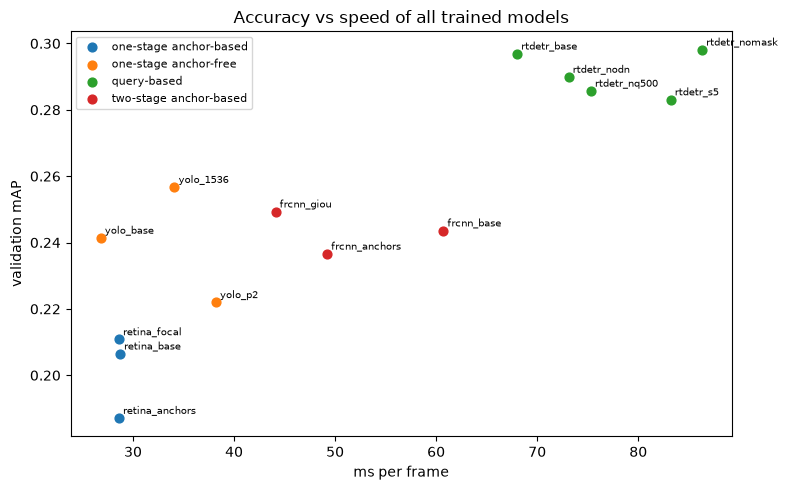

In [19]:
res = load_results().set_index("name")
family = {"frcnn": "two-stage anchor-based", "retina": "one-stage anchor-based", "yolo": "one-stage anchor-free",
          "rtdetr": "query-based"}
res["family"] = [next((v for k, v in family.items() if n.startswith(k)), "final pipeline") for n in res.index]
cols = ["family", "mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms_per_image"]
summary = res[cols].sort_values(["family", "mAP"], ascending=[True, False])
display(summary.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for fam, g in summary.dropna(subset=["ms_per_image"]).groupby("family"):
    ax.scatter(g.ms_per_image, g.mAP, label=fam, s=40)
    for n, r in g.iterrows():
        ax.annotate(n, (r.ms_per_image, r.mAP), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("ms per frame"); ax.set_ylabel("validation mAP"); ax.legend(fontsize=8)
ax.set_title("Accuracy vs speed of all trained models"); plt.tight_layout(); plt.show()

## 7. Small objects: larger input and sliced inference
AP_small stays around 0.13 for every model, and many test clips are low-resolution, so small objects are the main
remaining weakness. Two inference-only strategies for the fixed RT-DETR model:
* **larger input**: the full frame at 1600 instead of 1280;
* **sliced inference** (idea of SAHI, Akyon et al. 2022): 2x2 overlapping tiles (20 %), each resized to 1280, so
  small objects appear 1.5–3x larger; boxes touching an inner tile border are dropped (cut objects).
Tile/scale predictions are merged with the full-frame ones by class-wise NMS or by WBF. Selected on the validation
frames with `rtdetr_base` (trained on train clips only), then applied to the final model.

In [4]:
from common import nms_merge, wbf_merge

P_VAL["rt1600"] = cached("rtdetr_base_1600_val_preds.pkl", lambda: yu.predict_ultra(rt_base, ITEMS, imgsz=1600)[0])
P_VAL["rt_tiles"] = cached("rtdetr_base_tiles_val_preds.pkl", lambda: yu.predict_ultra_tiles(rt_base, ITEMS, imgsz=1280))

SCALE_RECIPES = {
    "full 1280 (as before)":          lambda P, S: P["rt"],
    "full 1600":                      lambda P, S: P["rt1600"],
    "tiles only":                     lambda P, S: P["rt_tiles"],
    "full 1280 + 1600, NMS":          lambda P, S: nms_merge([P["rt"], P["rt1600"]], 0.6),
    "full 1280 + tiles, NMS":         lambda P, S: nms_merge([P["rt"], P["rt_tiles"]], 0.6),
    "full 1280 + tiles, WBF":         lambda P, S: wbf_merge([P["rt"], P["rt_tiles"]], S, iou_thr=0.6),
    "full 1280 + 1600 + tiles, NMS":  lambda P, S: nms_merge([P["rt"], P["rt1600"], P["rt_tiles"]], 0.6),
    "full 1280 + 1600 + tiles, WBF":  lambda P, S: wbf_merge([P["rt"], P["rt1600"], P["rt_tiles"]], S, iou_thr=0.6),
}
rows = []
for name, fn in SCALE_RECIPES.items():
    m = coco_evaluate(VAL_GT, fn(P_VAL, SIZES))
    rows.append({"recipe": name, **{k: m[k] for k in KEYS}})
scale_tab = pd.DataFrame(rows).set_index("recipe").sort_values("mAP", ascending=False)
display(scale_tab.round(4))
close = scale_tab[scale_tab["mAP"] >= scale_tab["mAP"].max() - 0.005]
BEST_SCALE = close["AP_small"].idxmax()
print("selected:", BEST_SCALE)
save_results("final_scale_recipe_val", coco_evaluate(VAL_GT, SCALE_RECIPES[BEST_SCALE](P_VAL, SIZES)),
             recipe=BEST_SCALE, models="rtdetr_base (train clips only)")

,mAP,AP50,AP75,AP_small,AP_medium,AP_large
recipe,,,,,,
"full 1280 + 1600 + tiles, NMS",0.3061,0.5561,0.2954,0.1589,0.2831,0.4535
"full 1280 + tiles, NMS",0.3060,0.5575,0.2946,0.1649,0.2821,0.4531
"full 1280 + 1600 + tiles, WBF",0.3049,0.5556,0.2958,0.1559,0.2855,0.4594
"full 1280 + 1600, NMS",0.3022,0.5491,0.2937,0.1384,0.2766,0.4584
full 1600,0.3010,0.5423,0.2933,0.1337,0.2804,0.4501
"full 1280 + tiles, WBF",0.2985,0.5449,0.2849,0.1566,0.2793,0.4566
full 1280 (as before),0.2969,0.5400,0.2876,0.1326,0.2681,0.4592
tiles only,0.2623,0.4749,0.2550,0.1511,0.2515,0.4022


selected: full 1280 + tiles, NMS


{'name': 'final_scale_recipe_val',
 'mAP': 0.306,
 'AP50': 0.5575,
 'AP75': 0.2946,
 'AP_small': 0.1649,
 'AP_medium': 0.2821,
 'AP_large': 0.4531,
 'AP_person': 0.3108,
 'AP_bicycle': 0.2649,
 'AP_car': 0.5431,
 'AP_van': 0.308,
 'AP_truck': 0.3386,
 'AP_tricycle': 0.2921,
 'AP_bus': 0.2731,
 'AP_motor': 0.1176,
 'recipe': 'full 1280 + tiles, NMS',
 'models': 'rtdetr_base (train clips only)'}

In [5]:
# Apply the selected recipe with the final model (train + val clips)
if "1600" in BEST_SCALE:
    P_TEST["rt1600"] = cached("rtdetr_final_1600_test_preds.pkl", lambda: yu.predict_ultra(rt_final, T_ITEMS, imgsz=1600)[0])
if "tiles" in BEST_SCALE:
    P_TEST["rt_tiles"] = cached("rtdetr_final_tiles_test_preds.pkl", lambda: yu.predict_ultra_tiles(rt_final, T_ITEMS, imgsz=1280))
sub_g = SCALE_RECIPES[BEST_SCALE](P_TEST, T_SIZES)
write_submission(sub_g, test_df, SUB / "final_G_scale.csv")
submit(SUB / "final_G_scale.csv", f"Final G: RT-DETR train+val, {BEST_SCALE}")

100%|██████████| 56.3M/56.3M [00:07<00:00, 7.48MB/s]


Submission ref: 58139160
4 submissions remaining today.
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026